# PREDICTA AI — Advanced End-to-End Machine Learning

**Objective:** Estimate remaining useful life (RUL), in simulated operating cycles, using NASA C-MAPSS FD001 multivariate turbofan trajectories. The notebook is the complete, auditable research and machine-learning workflow; the separate Streamlit application consumes its serialized model.

**Source:** [NASA Open Data](https://data.nasa.gov/dataset/cmapss-jet-engine-simulated-data) and [GitHub dataset mirror](https://github.com/PunVas/nasa-c-mapss).

> **Important limitation:** NASA C-MAPSS data are physics-simulated, not measurements from a real fleet. Neither RUL estimates nor maintenance policies from this research demonstration are certified for live aircraft operations. No unmeasured model-performance results are claimed.

### Workflow
1. Problem definition, provenance and reproducible acquisition
2. Data audit, validation, cleaning and target construction
3. Visualization, EDA and statistical interpretation
4. Engine-disjoint data splitting and causal feature engineering
5. Regression baselines and nonlinear machine learning
6. Dimensionality reduction and feature selection
7. Group-aware hyperparameter tuning
8. Model selection, calibration and independent test evaluation
9. Interpretability, data drift and scenario investigation
10. Serialization, contract checks and application deployment

Markdown cells establish hypotheses, describe decisions and explain limitations; code cells execute the analysis. A shared `predicta/core.py` feature module is used by both this notebook and the deployed application to prevent training-serving skew.

## 0. Environment, configuration and reproducibility

Run **from the repository root** (the directory containing `predicta/` and `app.py`). Install the pinned-range dependencies once with `pip install -r requirements.txt`; then execute the notebook from top to bottom. Internet access is required only when downloading the raw NASA dataset for the first time.

The random seed makes group splitting and algorithm sampling reproducible under fixed library versions, but exact results can vary across computational environments.

In [1]:
# Optional one-time setup in Jupyter (uncomment and execute):
# %pip install -r requirements.txt

In [2]:
from __future__ import annotations

import hashlib
import json
import sys
import urllib.request
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Jupyter usually starts kernels in the notebook's own directory.
ROOT = Path.cwd()
if not (ROOT / 'predicta' / 'core.py').exists():
    ROOT = ROOT.parent
if not (ROOT / 'predicta' / 'core.py').exists():
    raise FileNotFoundError('Open this notebook inside the extracted PREDICTA_AI_v3_Release project.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from predicta.core import (
    RAW_COLUMNS, SETTINGS, SENSORS, ROLLING_SENSORS, WINDOW, FEATURES,
    load_trajectory, validate_raw, engineer_features, latest_snapshot,
    snapshot_at_fractions, regression_metrics, conformal_radius,
    predict_assets, assign_priority, population_stability_index,
)

SEED = 42
np.random.seed(SEED)
DATA_DIR = ROOT / 'data' / 'raw'
OUT = ROOT / 'artifacts'
SAMPLE_DIR = ROOT / 'data' / 'sample'
for directory in [DATA_DIR, OUT, SAMPLE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
print({'python':sys.version.split()[0], 'pandas':pd.__version__, 'sklearn':sklearn.__version__})

{'python': '3.13.0', 'pandas': '2.3.2', 'sklearn': '1.7.2'}


## 1. Problem definition, dataset and provenance

**Decision support question:** How many additional cycles might a monitored engine operate before the simulated end-of-life target, and which assets warrant earlier engineering review?

**Target:** Continuous RUL in cycles. In the complete *training* trajectories, the target for a row is `engine_max_cycle - current_cycle`. Test trajectories are truncated; their true remaining life is supplied separately in `RUL_FD001.txt`. **Never derive test labels from their last observed cycle.**

**Primary prediction unit:** One snapshot at the latest available cycle of an engine. Metrics on the official test set must therefore be calculated **once per engine**, not on every sensor row.

**Evaluation:** MAE, RMSE, R², optional NASA asymmetric prognostic score, and empirical coverage of prediction intervals. Calibration-based uncertainty is conditional on the calibration cohort resembling the evaluation cohort.

Dataset is FD001 (one operating condition, one fault mode), not four FD00X domains pooled together.

In [3]:
SOURCE_REPO = 'https://github.com/PunVas/nasa-c-mapss'
RAW_BASE = 'https://raw.githubusercontent.com/PunVas/nasa-c-mapss/main'
REQUIRED = ('train_FD001.txt', 'test_FD001.txt', 'RUL_FD001.txt')

def fetch_data(filename: str) -> Path:
    target = DATA_DIR / filename
    if target.exists() and target.stat().st_size:
        return target
    url = f'{RAW_BASE}/{filename}'
    print('Retrieving', url)
    try:
        with urllib.request.urlopen(url, timeout=60) as response:
            payload = response.read()
        if not payload:
            raise RuntimeError('Response was empty')
        target.write_bytes(payload)
    except Exception as exc:
        raise RuntimeError(f'Unable to fetch {filename}. Download it from {SOURCE_REPO} '
                           f'into {DATA_DIR} and retry. Original error: {exc}') from exc
    return target

paths = {name:fetch_data(name) for name in REQUIRED}
manifest = {name:{'bytes':p.stat().st_size,'sha256':hashlib.sha256(p.read_bytes()).hexdigest()}
            for name,p in paths.items()}
print(json.dumps(manifest,indent=2))

{
  "train_FD001.txt": {
    "bytes": 3515356,
    "sha256": "963b5e22825b34d8b21c69e1aeb4af3e647050eb672ee8834ba4b5d91d2de0f8"
  },
  "test_FD001.txt": {
    "bytes": 2228855,
    "sha256": "3cda7109ce17bafb5443f2ac926cfcf88154b941b8c4cf95eb55d1ddd6f52851"
  },
  "RUL_FD001.txt": {
    "bytes": 429,
    "sha256": "a19c8ec94931949d0485bdc35118206e9c81c4547b422efb9cf86f4ceddbceca"
  }
}


In [4]:
train_raw = load_trajectory(paths['train_FD001.txt'])
test_raw = load_trajectory(paths['test_FD001.txt'])
truth = pd.read_csv(paths['RUL_FD001.txt'],sep=r'\s+',header=None).iloc[:,0].to_numpy(dtype=float)
test_engine_ids = np.sort(test_raw.engine_id.unique())
if len(truth)!=len(test_engine_ids):
    raise ValueError('Number of true RUL values differs from test engine count.')
# NASA documentation orders official RUL labels by test engine id.
assert np.array_equal(test_engine_ids,np.arange(1,len(truth)+1)), 'Unexpected test engine ID mapping.'
print('Train rows:',len(train_raw),'Training engines:',train_raw.engine_id.nunique())
print('Test rows:',len(test_raw),'Test engines:',test_raw.engine_id.nunique())
display(train_raw.head())

Train rows: 20631 Training engines: 100
Test rows: 13096 Test engines: 100


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 2. Data quality, validation and preprocessing

An engineering-grade pipeline must detect schema failures rather than automatically dropping invalid records. Verify positive integral engine IDs/cycles, unique `(engine_id, cycle)` keys, finite numeric values and absence of missing readings.

Outliers can reflect real degradation; blindly removing them would destroy valuable signal. We also identify constant or near-constant channels before deciding whether removal is helpful. Feature scaling and imputation belong **inside sklearn pipelines**, fitted to training data only.

In [5]:
def audit(frame: pd.DataFrame, name: str) -> pd.DataFrame:
    summary = pd.DataFrame({'dtype':frame.dtypes.astype(str), 'missing':frame.isna().sum(),
                            'missing_pct':100*frame.isna().mean(),
                            'unique':frame.nunique(), 'std':frame.std(numeric_only=True)})
    print(f'{name}: {len(frame):,} rows; duplicate engine-cycle keys:',
          int(frame.duplicated(['engine_id','cycle']).sum()))
    display(summary.head(15))
    return summary

train_audit = audit(train_raw,'TRAIN')
test_audit = audit(test_raw,'TEST')
constant_channels = train_raw[SENSORS+SETTINGS].nunique().loc[lambda x:x<=1].index.tolist()
print('Constant signals, identified from training data only:',constant_channels)
assert train_raw[RAW_COLUMNS].notna().all().all()
assert test_raw[RAW_COLUMNS].notna().all().all()

TRAIN: 20,631 rows; duplicate engine-cycle keys: 0


,dtype,missing,missing_pct,unique,std
engine_id,int64,0,0.0,100,2.922763e+01
cycle,int64,0,0.0,362,6.888099e+01
setting_1,float64,0,0.0,158,2.187313e-03
setting_2,float64,0,0.0,13,2.930621e-04
setting_3,float64,0,0.0,1,0.000000e+00
sensor_1,float64,0,0.0,1,0.000000e+00
sensor_2,float64,0,0.0,310,5.000533e-01
sensor_3,float64,0,0.0,3012,6.131150e+00
sensor_4,float64,0,0.0,4051,9.000605e+00
sensor_5,float64,0,0.0,1,5.329200e-15


TEST: 13,096 rows; duplicate engine-cycle keys: 0


,dtype,missing,missing_pct,unique,std
engine_id,int64,0,0.0,100,2.828942e+01
cycle,int64,0,0.0,303,5.305775e+01
setting_1,float64,0,0.0,150,2.202685e-03
setting_2,float64,0,0.0,14,2.940306e-04
setting_3,float64,0,0.0,1,0.000000e+00
sensor_1,float64,0,0.0,1,0.000000e+00
sensor_2,float64,0,0.0,262,4.008993e-01
sensor_3,float64,0,0.0,2361,5.003274e+00
sensor_4,float64,0,0.0,2954,6.688309e+00
sensor_5,float64,0,0.0,1,1.776425e-15


Constant signals, identified from training data only: ['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19', 'setting_3']


In [6]:
train_labeled = train_raw.copy()
train_labeled['rul'] = (train_labeled.groupby('engine_id')['cycle'].transform('max')
                        - train_labeled['cycle'])
assert train_labeled.rul.ge(0).all()
assert train_labeled.groupby('engine_id').tail(1).rul.eq(0).all()
print('Training RUL summary:')
display(train_labeled.rul.describe().to_frame('RUL (cycles)'))

Training RUL summary:


,RUL (cycles)
count,20631.000000
mean,107.807862
std,68.880990
min,0.000000
25%,51.000000
50%,103.000000
75%,155.000000
max,361.000000


## 3. Data visualization and exploratory data analysis

First assess trajectory lengths, RUL distribution, measured channel variance and degradation patterns. Interpret correlation as an association, not evidence of physical causation. **All exploratory plots use training observations only** so the official test set stays untouched.

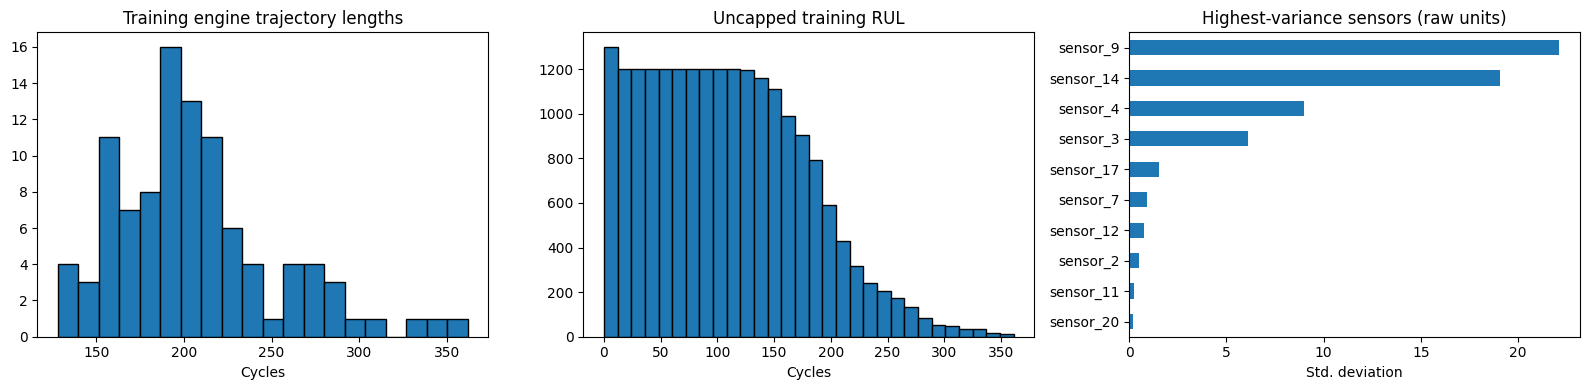

Interpretation: variances between sensors are not directly comparable without normalization.


In [7]:
lengths = train_raw.groupby('engine_id').cycle.max()
fig,ax = plt.subplots(1,3,figsize=(16,4))
ax[0].hist(lengths,bins=20,edgecolor='black');ax[0].set(title='Training engine trajectory lengths',xlabel='Cycles')
ax[1].hist(train_labeled.rul,bins=30,edgecolor='black');ax[1].set(title='Uncapped training RUL',xlabel='Cycles')
stds = train_raw[SENSORS].std().sort_values(ascending=False)
stds.head(10).sort_values().plot.barh(ax=ax[2]);ax[2].set(title='Highest-variance sensors (raw units)',xlabel='Std. deviation')
plt.tight_layout();plt.show()
print('Interpretation: variances between sensors are not directly comparable without normalization.')

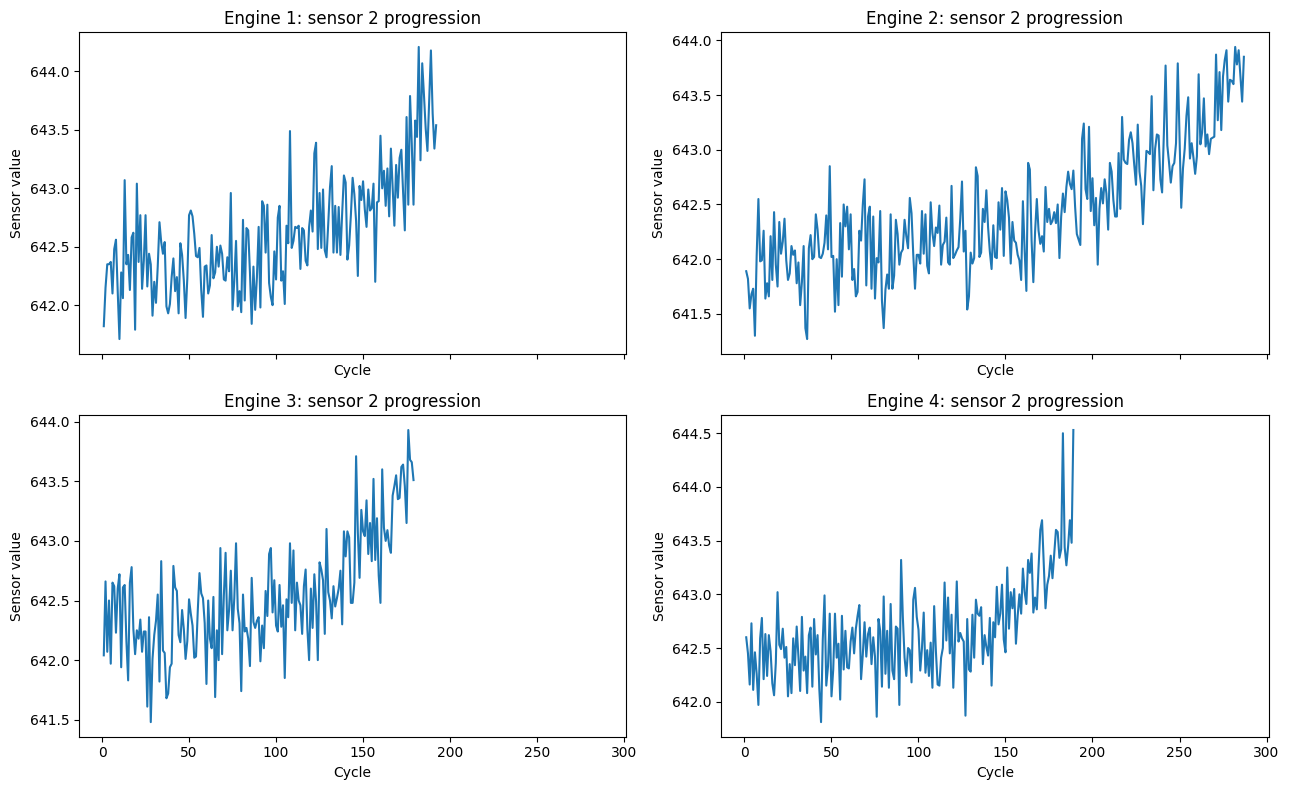

,Pearson r
cycle,-0.736241
sensor_11,-0.696228
sensor_4,-0.678948
sensor_15,-0.642667
sensor_2,-0.606484
sensor_17,-0.606154
sensor_3,-0.584520


,Pearson r
sensor_12,0.671983
sensor_1,NaN
sensor_5,NaN
sensor_10,NaN
sensor_16,NaN
sensor_18,NaN
sensor_19,NaN


In [8]:
fig,axs=plt.subplots(2,2,figsize=(13,8),sharex=True)
selected_engines=train_raw.engine_id.unique()[:4]
for a,eid in zip(axs.flat,selected_engines):
    segment=train_labeled.loc[train_labeled.engine_id.eq(eid)]
    a.plot(segment.cycle,segment.sensor_2,label='sensor_2',lw=1.5)
    a.set(title=f'Engine {eid}: sensor 2 progression',xlabel='Cycle',ylabel='Sensor value')
plt.tight_layout();plt.show()
association=(train_labeled[SENSORS+['cycle','rul']]
             .corr(numeric_only=True)['rul'].drop('rul').sort_values())
display(association.to_frame('Pearson r').head(7))
display(association.to_frame('Pearson r').tail(7))

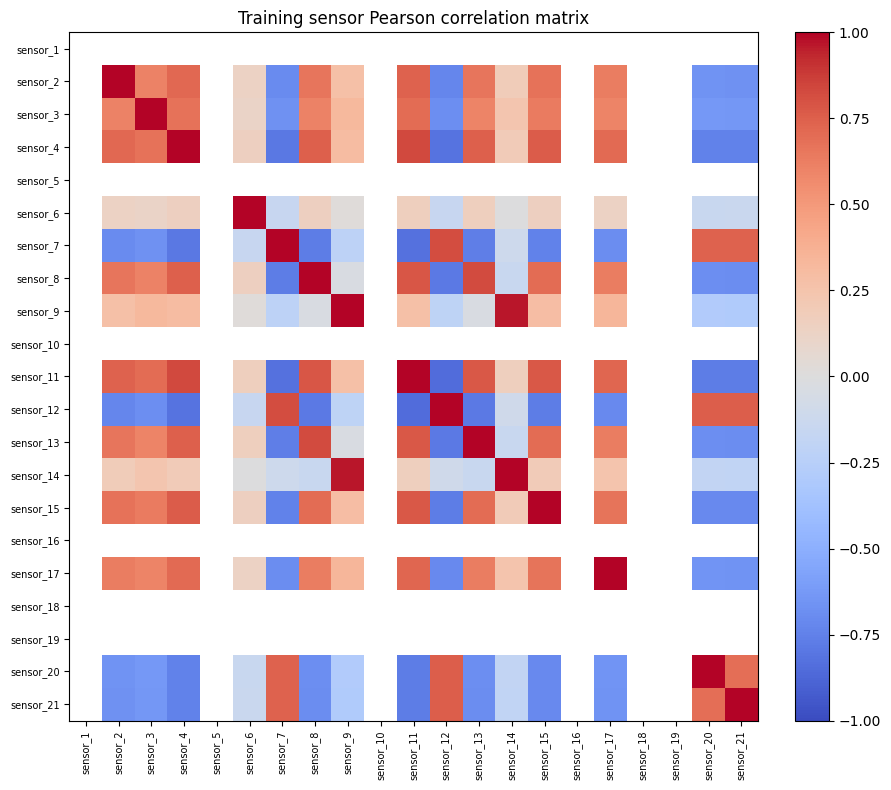

Finding to investigate: redundancy between sensor channels may make PCA or feature selection useful.


In [9]:
corr=train_labeled[SENSORS].corr(numeric_only=True)
fig,ax=plt.subplots(figsize=(10,8))
im=ax.imshow(corr.to_numpy(),cmap='coolwarm',vmin=-1,vmax=1)
ax.set_xticks(range(len(SENSORS)),SENSORS,rotation=90,fontsize=7)
ax.set_yticks(range(len(SENSORS)),SENSORS,fontsize=7)
fig.colorbar(im,ax=ax,fraction=.046,pad=.04)
ax.set_title('Training sensor Pearson correlation matrix')
plt.tight_layout();plt.show()
print('Finding to investigate: redundancy between sensor channels may make PCA or feature selection useful.')

## 4. Engine-disjoint splitting and causal feature engineering

**Three independent internal partitions:** training engines, model-selection engines, and calibration engines. No engine may appear in more than one partition. The **official NASA test engines remain separate from all three**.

Feature engineering uses previous/current cycles only: rolling mean, rolling standard deviation and change over the last five available samples for eight selected sensors. All preprocessing transforms for ML models are fitted inside the pipeline.

We train on nine snapshots per engine (20–100% trajectory fractions) to reduce long-engine row dominance; validate on three snapshots (45%, 65%, 85%); calibrate at one deterministic, varied snapshot per engine. These choices are explicit experimental assumptions. Calibration snapshots may not match the NASA test truncation distribution, so interval coverage must be checked and should not be presented as guaranteed.

In [10]:
# Split ENGINE IDs, not sensor-row observations.
engines=np.sort(train_labeled.engine_id.unique())
first=GroupShuffleSplit(n_splits=1,test_size=0.30,random_state=SEED)
train_pos,held_pos=next(first.split(engines,groups=engines))
train_ids=engines[train_pos]
held_ids=engines[held_pos]
second=GroupShuffleSplit(n_splits=1,test_size=0.50,random_state=SEED+1)
val_pos,cal_pos=next(second.split(held_ids,groups=held_ids))
val_ids,cal_ids=held_ids[val_pos],held_ids[cal_pos]
assert not (set(train_ids)&set(val_ids) or set(train_ids)&set(cal_ids) or set(val_ids)&set(cal_ids))
print('Training engines:',len(train_ids),'Validation engines:',len(val_ids),'Calibration engines:',len(cal_ids))

# Shared feature engine is imported from predicta.core and reused in app.py.
train_featured=engineer_features(train_raw)
train_featured['rul']=train_labeled.rul.to_numpy()
test_featured=engineer_features(test_raw)
print('Raw features:',len(RAW_COLUMNS),'Engineered modeling features:',len(FEATURES))
display(train_featured[["engine_id","cycle","sensor_2","sensor_2_mean5","sensor_2_std5","sensor_2_delta5","rul"]].head(8))

Training engines: 70 Validation engines: 15 Calibration engines: 15


Raw features: 26 Engineered modeling features: 49


,engine_id,cycle,sensor_2,sensor_2_mean5,sensor_2_std5,sensor_2_delta5,rul
0,1,1,641.82,641.820000,0.000000,0.00,191
1,1,2,642.15,641.985000,0.233345,0.33,190
2,1,3,642.35,642.106667,0.267644,0.53,189
3,1,4,642.35,642.167500,0.250117,0.53,188
4,1,5,642.37,642.208000,0.234776,0.55,187
5,1,6,642.10,642.264000,0.128374,-0.05,186
6,1,7,642.48,642.330000,0.139463,0.13,185
7,1,8,642.56,642.372000,0.174270,0.21,184


In [11]:
train_pool=train_featured[train_featured.engine_id.isin(train_ids)]
val_pool=train_featured[train_featured.engine_id.isin(val_ids)]
cal_pool=train_featured[train_featured.engine_id.isin(cal_ids)]
TRAIN_FRACTIONS=(.20,.30,.40,.50,.60,.70,.80,.90,1.0)
VALIDATION_FRACTIONS=(.45,.65,.85)
train_set=snapshot_at_fractions(train_pool,TRAIN_FRACTIONS)
val_set=snapshot_at_fractions(val_pool,VALIDATION_FRACTIONS)
# Exactly one calibration snapshot PER ENGINE to avoid dependent residuals.
cal_parts=[]
for engine_id,group in cal_pool.groupby('engine_id',sort=True):
    frac=(.40,.55,.70,.85)[int(engine_id)%4]
    cal_parts.append(snapshot_at_fractions(group,(frac,)))
cal_set=pd.concat(cal_parts,ignore_index=True)

X_train,y_train=train_set[FEATURES],train_set.rul
groups_train=train_set.engine_id
X_val,y_val=val_set[FEATURES],val_set.rul
X_cal,y_cal=cal_set[FEATURES],cal_set.rul
print('Training/validation/calibration snapshots:',len(train_set),len(val_set),len(cal_set))
assert X_train.columns.tolist()==FEATURES
assert set(train_set.engine_id).isdisjoint(set(val_set.engine_id))
assert set(val_set.engine_id).isdisjoint(set(cal_set.engine_id))

Training/validation/calibration snapshots: 630 45 15


## 5. Machine learning — baseline and model comparison

Begin with DummyRegressor to establish a minimal predictive benchmark; then compare linear regression and tree ensembles. The model is chosen based on **internal validation MAE** at consistent sample fractions; official NASA test labels are not used for selection. We clip negative RUL predictions to zero only when reporting or deploying results.

In [12]:
models={
 'Dummy mean': Pipeline([('impute',SimpleImputer(strategy='median')),
                         ('model',DummyRegressor(strategy='mean'))]),
 'Ridge':Pipeline([('impute',SimpleImputer(strategy='median')),
                   ('scale',StandardScaler()),('model',Ridge(alpha=20))]),
 'Random forest':Pipeline([('impute',SimpleImputer(strategy='median')),
                            ('model',RandomForestRegressor(n_estimators=150,min_samples_leaf=3,
                                                           random_state=SEED,n_jobs=-1))]),
 'Histogram gradient boosting':Pipeline([('impute',SimpleImputer(strategy='median')),
                                 ('model',HistGradientBoostingRegressor(max_iter=160,
                                          max_leaf_nodes=15,early_stopping=False,random_state=SEED))])
}
results={}
for name,mdl in models.items():
    mdl.fit(X_train,y_train)
    guess=np.maximum(0,mdl.predict(X_val))
    results[name]=regression_metrics(y_val,guess)
comparison=pd.DataFrame(results).T.sort_values('MAE')
display(comparison.round(3))

,MAE,RMSE,R2
Random forest,18.080,23.763,0.613
Ridge,19.580,23.816,0.611
Histogram gradient boosting,21.835,27.958,0.464
Dummy mean,33.600,39.439,-0.066


## 6. Dimensionality reduction and feature selection

**PCA** tests whether lower-dimensional representations of correlated features help a regularized linear model. **SelectKBest** tests whether a subset of original variables retains adequate predictive information. Both transformations are fitted only on training snapshots inside sklearn Pipelines; no PCA or SelectKBest calculation may see validation, calibration or test targets.

Dimensionality reduction is an experiment, not a universal prerequisite. Compare these methods against the unmodified baseline.

In [13]:
reduced={
 'Ridge + PCA(95%)': Pipeline([('impute',SimpleImputer(strategy='median')),
        ('scale',StandardScaler()),('pca',PCA(n_components=.95)),('model',Ridge(alpha=20))]),
 'Ridge + SelectKBest(16)':Pipeline([('impute',SimpleImputer(strategy='median')),
        ('scale',StandardScaler()),('select',SelectKBest(score_func=f_regression,k=16)),
        ('model',Ridge(alpha=20))]),
}
for name,mdl in reduced.items():
    mdl.fit(X_train,y_train)
    models[name]=mdl
    results[name]=regression_metrics(y_val,np.maximum(0,mdl.predict(X_val)))
display(pd.DataFrame(results).T.sort_values('MAE').round(3))
select=reduced['Ridge + SelectKBest(16)'].named_steps['select']
print('Selected columns:',np.array(FEATURES)[select.get_support()].tolist())
print('PCA components:',reduced['Ridge + PCA(95%)'].named_steps['pca'].n_components_)

,MAE,RMSE,R2
Random forest,18.080,23.763,0.613
Ridge,19.580,23.816,0.611
Ridge + PCA(95%),19.870,24.222,0.598
Ridge + SelectKBest(16),21.500,25.753,0.545
Histogram gradient boosting,21.835,27.958,0.464
Dummy mean,33.600,39.439,-0.066


Selected columns: ['sensor_2', 'sensor_4', 'sensor_7', 'sensor_11', 'sensor_12', 'sensor_15', 'sensor_20', 'sensor_21', 'sensor_2_mean5', 'sensor_3_mean5', 'sensor_4_mean5', 'sensor_7_mean5', 'sensor_11_mean5', 'sensor_12_mean5', 'sensor_15_mean5', 'sensor_20_mean5']
PCA components: 22


## 7. Hyperparameter tuning with grouped cross-validation

Use `GroupKFold` on training snapshots, grouped by engine ID. The entire imputation and modeling pipeline is refitted in each fold. This approach prevents sensor records from the same engine appearing in both the training and validation side of a CV fold.

**Scoring nuance:** each training engine contributes nine snapshots, giving comparable row weights across engines; this CV objective still differs from official test evaluation, which scores exactly one endpoint per test engine.

In [14]:
tunable=Pipeline([('impute',SimpleImputer(strategy='median')),
                  ('model',HistGradientBoostingRegressor(early_stopping=False,random_state=SEED))])
search=RandomizedSearchCV(
    tunable,
    {'model__max_iter':[100,150,220], 'model__max_leaf_nodes':[8,15,25],
     'model__learning_rate':[.035,.06,.1], 'model__min_samples_leaf':[10,20,35],
     'model__l2_regularization':[0.0,.2,1.0]},
    n_iter=8, scoring='neg_mean_absolute_error',
    cv=GroupKFold(n_splits=3), n_jobs=1, random_state=SEED, refit=True
)
search.fit(X_train,y_train,groups=groups_train)
print('Best grouped CV MAE:',round(-search.best_score_,3))
print('Selected hyperparameters:',search.best_params_)
models['Tuned gradient boosting']=search.best_estimator_
results['Tuned gradient boosting']=regression_metrics(y_val,
    np.maximum(0,search.best_estimator_.predict(X_val)))
display(pd.DataFrame(results).T.sort_values('MAE').round(3))

Best grouped CV MAE: 22.701
Selected hyperparameters: {'model__min_samples_leaf': 20, 'model__max_leaf_nodes': 15, 'model__max_iter': 150, 'model__learning_rate': 0.035, 'model__l2_regularization': 1.0}


,MAE,RMSE,R2
Random forest,18.080,23.763,0.613
Tuned gradient boosting,19.041,25.055,0.570
Ridge,19.580,23.816,0.611
Ridge + PCA(95%),19.870,24.222,0.598
Ridge + SelectKBest(16),21.500,25.753,0.545
Histogram gradient boosting,21.835,27.958,0.464
Dummy mean,33.600,39.439,-0.066


## 8. Select a model using validation engines only

Compare validation metrics on held-out engines. Keep a single chosen configuration, then refit it on training **plus validation** groups. Calibration groups remain unused until the following prediction-interval stage. The official NASA test set is not inspected for model selection.

In [15]:
model_comparison=(pd.DataFrame(results).T.sort_values('MAE')
                  .reset_index().rename(columns={'index':'Model','MAE':'Validation_MAE',
                                                  'RMSE':'Validation_RMSE','R2':'Validation_R2'}))
display(model_comparison.round(3))
chosen_name=model_comparison.iloc[0]['Model']
chosen=clone(models[chosen_name])
fit_pool=pd.concat([train_set,val_set],ignore_index=True)
chosen.fit(fit_pool[FEATURES],fit_pool.rul)
print('Model selected without test data:',chosen_name)
print('Refit observations and unique engines:',len(fit_pool),fit_pool.engine_id.nunique())

,Model,Validation_MAE,Validation_RMSE,Validation_R2
0,Random forest,18.080,23.763,0.613
1,Tuned gradient boosting,19.041,25.055,0.570
2,Ridge,19.580,23.816,0.611
3,Ridge + PCA(95%),19.870,24.222,0.598
4,Ridge + SelectKBest(16),21.500,25.753,0.545
5,Histogram gradient boosting,21.835,27.958,0.464
6,Dummy mean,33.600,39.439,-0.066


Model selected without test data: Random forest
Refit observations and unique engines: 675 85


## 9. Prediction interval calibration on separate engines

A point estimate alone hides model uncertainty. Use the absolute residuals on **one snapshot per calibration engine** to form a split-conformal interval radius at a nominal 90% level, applying the finite-sample `ceil((n+1)*(1-alpha))` rank correction.

The calibration cohort includes different fractions of completed trajectories, whereas the official NASA test observations are truncated at unobserved life fractions. Therefore the usual distributional similarity / exchangeability premise may fail and the nominal 90% level is **not guaranteed on those test endpoints or on deployed assets**. We will report empirical test coverage as a diagnostic.

Calibration engines: 15
Absolute error interval radius (cycles): 82.6
Empirical internal calibration coverage: 1.0


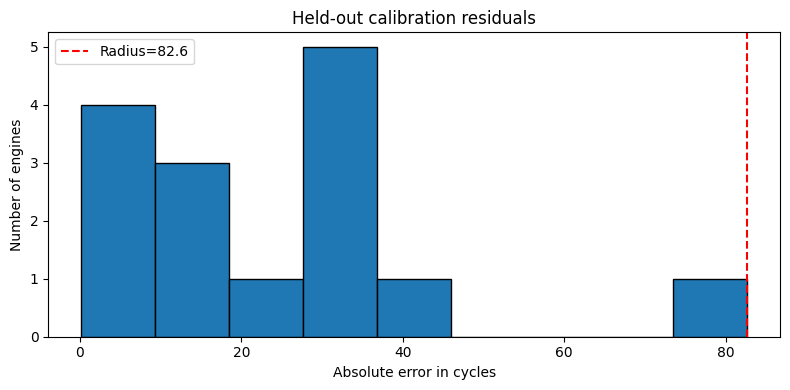

In [16]:
ALPHA=.10
cal_predictions=np.maximum(0,chosen.predict(X_cal))
radius=conformal_radius(y_cal,cal_predictions,alpha=ALPHA)
cal_lower=np.maximum(0,cal_predictions-radius)
cal_upper=cal_predictions+radius
cal_coverage=float(np.mean((y_cal.to_numpy()>=cal_lower)&(y_cal.to_numpy()<=cal_upper)))
print('Calibration engines:',len(cal_set))
print('Absolute error interval radius (cycles):',round(radius,2))
print('Empirical internal calibration coverage:',round(cal_coverage,3))
fig,ax=plt.subplots(figsize=(8,4))
ax.hist(np.abs(y_cal.to_numpy()-cal_predictions),bins=9,edgecolor='black')
ax.axvline(radius,color='red',linestyle='--',label=f'Radius={radius:.1f}')
ax.set(title='Held-out calibration residuals',xlabel='Absolute error in cycles',ylabel='Number of engines');ax.legend()
plt.tight_layout();plt.show()

## 10. Independent official NASA test evaluation

With model selection and calibration frozen, score each official test engine at its **last observed** cycle. Compare predictions against the provided `RUL_FD001.txt` ground truth. Score once per engine and retain the raw RUL target (we do **not** cap labels during modeling).

The optional NASA asymmetric score penalizes dangerous RUL overestimation more strongly than underestimation. Test metrics are genuine only after executing this cell with the real dataset.

In [17]:
official_test=latest_snapshot(test_featured)
assert np.array_equal(official_test.engine_id.to_numpy(),test_engine_ids)
response=np.maximum(0,chosen.predict(official_test[FEATURES]))
metrics=regression_metrics(truth,response)

def nasa_asymmetric_score(y_true,y_pred):
    err=np.asarray(y_pred)-np.asarray(y_true)
    return float(np.sum(np.where(err<0,np.exp(np.clip(-err/13,-100,100))-1,
                                 np.exp(np.clip(err/10,-100,100))-1)))
metrics['NASA_asymmetric_score']=nasa_asymmetric_score(truth,response)
low=np.maximum(0,response-radius)
high=response+radius
metrics['empirical_test_interval_coverage']=float(((truth>=low)&(truth<=high)).mean())
metrics['mean_test_interval_width']=float((high-low).mean())
print('Official test engine count:',len(truth))
print(json.dumps(metrics,indent=2))

test_results=official_test[['engine_id','cycle']].copy()
test_results['true_rul']=truth
test_results['predicted_rul']=response
test_results['rul_lower']=low
test_results['rul_upper']=high
test_results['absolute_error']=abs(response-truth)
display(test_results.head(10))

Official test engine count: 100
{
  "MAE": 17.605392778876904,
  "RMSE": 22.653027148976847,
  "R2": 0.7028382229832049,
  "NASA_asymmetric_score": 1629.6655705432963,
  "empirical_test_interval_coverage": 1.0,
  "mean_test_interval_width": 146.064831690597
}


,engine_id,cycle,true_rul,predicted_rul,rul_lower,rul_upper,absolute_error
0,1,31,112.0,144.678161,62.074768,227.281555,32.678161
1,2,49,98.0,141.779187,59.175793,224.382580,43.779187
2,3,126,69.0,51.250070,0.000000,133.853464,17.749930
3,4,106,82.0,69.114141,0.000000,151.717534,12.885859
4,5,98,91.0,106.617448,24.014055,189.220842,15.617448
5,6,105,93.0,97.356430,14.753037,179.959823,4.356430
6,7,160,91.0,107.826183,25.222790,190.429577,16.826183
7,8,166,95.0,75.050811,0.000000,157.654204,19.949189
8,9,55,111.0,125.861539,43.258146,208.464933,14.861539
9,10,192,96.0,103.399674,20.796281,186.003067,7.399674


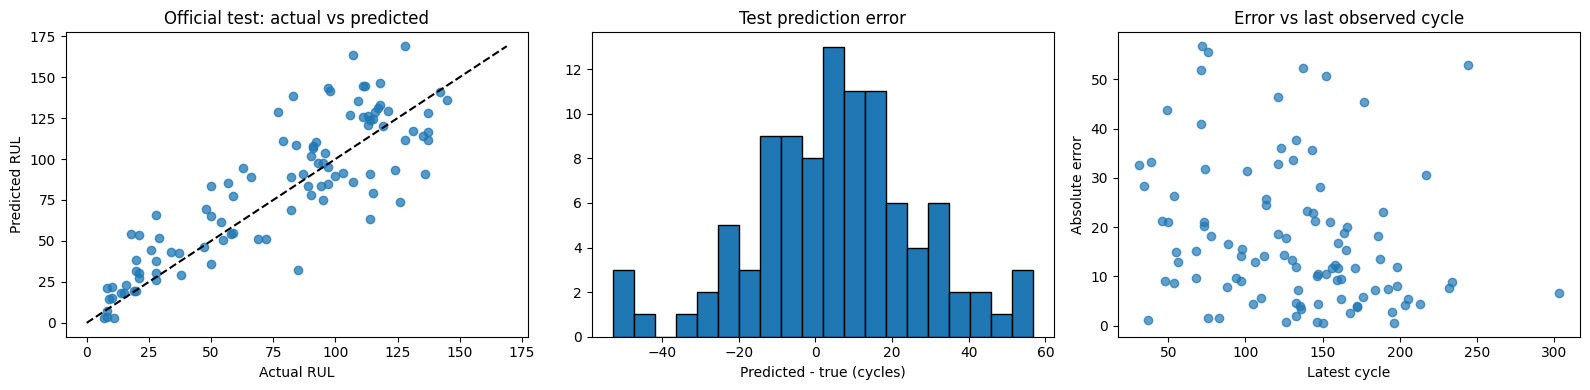

Interpretation: investigate potential systematic under/overprediction and calibration shift.


In [18]:
fig,axs=plt.subplots(1,3,figsize=(16,4))
axs[0].scatter(test_results.true_rul,test_results.predicted_rul,alpha=.75)
lims=[0,max(test_results.true_rul.max(),test_results.predicted_rul.max())]
axs[0].plot(lims,lims,'--',color='black');axs[0].set(xlabel='Actual RUL',ylabel='Predicted RUL',title='Official test: actual vs predicted')
axs[1].hist(test_results.predicted_rul-test_results.true_rul,bins=20,edgecolor='black')
axs[1].set(title='Test prediction error',xlabel='Predicted - true (cycles)')
axs[2].scatter(test_results.cycle,test_results.absolute_error,alpha=.7)
axs[2].set(title='Error vs last observed cycle',xlabel='Latest cycle',ylabel='Absolute error')
plt.tight_layout();plt.show()
print('Interpretation: investigate potential systematic under/overprediction and calibration shift.')

## 11. Explainable ML and error analysis

Permutation importance on the **internal validation snapshots** measures the increase in MAE after randomly shuffling each input feature while other features are held fixed. It works across PCA, linear and tree pipelines, but correlated features can divide importance between themselves. These scores are **not causal explanations**, and the small validation sample can be noisy.

To avoid the risk of test leakage, we do not use official test labels for importance ranking or feature selection.

,feature,mae_increase,std
37,sensor_11_mean5,8.972588,1.860516
0,cycle,2.914452,1.517223
31,sensor_4_mean5,2.172355,0.759871
12,sensor_9,2.159012,0.397256
43,sensor_15_mean5,2.134329,0.628240
34,sensor_7_mean5,1.367620,0.396100
25,sensor_2_mean5,1.230604,0.390976
27,sensor_2_delta5,1.094079,0.178304
7,sensor_4,1.038500,0.316131
28,sensor_3_mean5,0.981074,0.380237


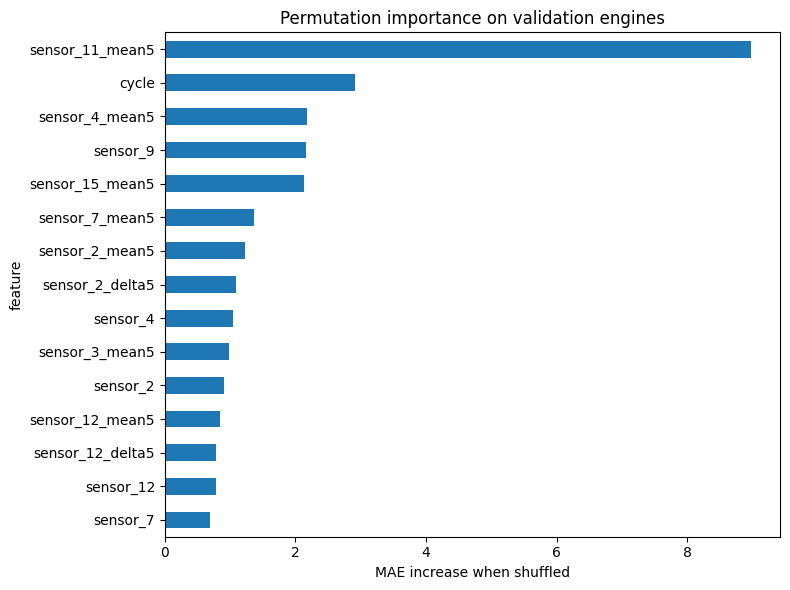

In [19]:
# Explain the refit selected model without using calibration or official test labels.
importance_result=permutation_importance(chosen,X_val,y_val,scoring='neg_mean_absolute_error',
                                          n_repeats=7,random_state=SEED,n_jobs=1)
imp=pd.DataFrame({'feature':FEATURES,'mae_increase':importance_result.importances_mean,
                  'std':importance_result.importances_std}).sort_values('mae_increase',ascending=False)
display(imp.head(15))
fig,ax=plt.subplots(figsize=(8,6))
imp.head(15).iloc[::-1].plot.barh(x='feature',y='mae_increase',ax=ax,legend=False)
ax.set(title='Permutation importance on validation engines',xlabel='MAE increase when shuffled')
plt.tight_layout();plt.show()

## 12. Covariate drift and model applicability diagnostics

Inspect possible differences in selected feature distributions between training-reference engine endpoints and test engine endpoints using **population stability index (PSI)**. This is only a descriptive, sample-size-sensitive measure here; do not interpret conventional PSI thresholds as calibrated failure alarms. Important: these calculations use test **features only** and do not affect the selected model.

In [20]:
DRIFT_FEATURES=['cycle','sensor_2','sensor_4','sensor_7','sensor_11','sensor_12']
reference=latest_snapshot(train_featured[train_featured.engine_id.isin(train_ids)])[DRIFT_FEATURES]
drift_table=pd.DataFrame([{'feature':col,
 'PSI_training_endpoint_vs_official_test':population_stability_index(reference[col],official_test[col])}
 for col in DRIFT_FEATURES]).sort_values('PSI_training_endpoint_vs_official_test',ascending=False)
display(drift_table)
print('Any drift scores are monitoring diagnostics, not validated thresholds.')

,feature,PSI_training_endpoint_vs_official_test
4,sensor_11,9.670053
2,sensor_4,9.535964
1,sensor_2,6.941487
5,sensor_12,6.851156
3,sensor_7,6.481224
0,cycle,1.858909


Any drift scores are monitoring diagnostics, not validated thresholds.


### 12A. Baseline sensor deviations and controlled sensitivity checks

A robust median/MAD baseline computed from training engines can help identify **unusual numerical readings**, but unusual is not synonymous with engine failure. Some sensor channels are constant or nearly constant and must not be scored with a zero denominator.

A second engineering experiment perturbs one sensor over the most recent five cycles, recomputes the same causal features and observes the RUL change. This estimates **model sensitivity**, not a physical intervention or causal effect. The application exposes it as an optional diagnostic and explicitly labels these limitations.

In [21]:
training_reference_rows=train_raw[train_raw.engine_id.isin(train_ids)]
sensor_stats={}
for sensor in SENSORS:
    v=training_reference_rows[sensor]
    med=float(v.median())
    sensor_stats[sensor]={'median':med,'mad':float(np.median(np.abs(v-med))),
                          'std':float(v.std(ddof=0))}

example_engine=int(test_engine_ids[0])
most_recent=latest_snapshot(test_featured)
probe=most_recent[most_recent.engine_id.eq(example_engine)].iloc[0]
screen=[]
for sensor,stat in sensor_stats.items():
    scale=1.4826*stat['mad']
    if scale>1e-10:
        screen.append({'sensor':sensor,'robust_deviation':abs(float(probe[sensor])-stat['median'])/scale})
print('Largest descriptive deviations for a single official test engine:')
display(pd.DataFrame(screen).sort_values('robust_deviation',ascending=False).head(10))

temporary_bundle={'model':chosen,'feature_names':FEATURES,'conformal_radius':radius}
base_predictions,_=predict_assets(test_raw,temporary_bundle)
sensor_to_perturb='sensor_2'
sigma=sensor_stats[sensor_to_perturb]['std']
shifted=test_raw.copy()
positions=(shifted[shifted.engine_id.eq(example_engine)].sort_values('cycle').tail(WINDOW).index)
shifted.loc[positions,sensor_to_perturb]+=0.5*sigma
shift_predictions,_=predict_assets(shifted,temporary_bundle)
before=float(base_predictions.loc[base_predictions.engine_id.eq(example_engine),'rul_estimate'].iloc[0])
after=float(shift_predictions.loc[shift_predictions.engine_id.eq(example_engine),'rul_estimate'].iloc[0])
print('Controlled sensor sensitivity: baseline=',round(before,2),'shifted=',round(after,2),
      'difference=',round(after-before,2),'cycles')
print('This is MODEL sensitivity only, not a physically validated scenario.')

Largest descriptive deviations for a single official test engine:


,sensor,robust_deviation
1,sensor_3,1.484218
6,sensor_11,1.110926
3,sensor_7,1.104769
2,sensor_4,1.016889
9,sensor_14,1.008498
10,sensor_15,0.973660
13,sensor_21,0.522493
7,sensor_12,0.407505
8,sensor_13,0.404694
5,sensor_9,0.397559


Controlled sensor sensitivity: baseline= 144.68 shifted= 148.91 difference= 4.24 cycles
This is MODEL sensitivity only, not a physically validated scenario.


## 13. Maintenance prioritization and transparent policy experiments

A user-adjustable illustrative policy can rank assets based on **both the RUL estimate and its interval bounds**:
- `Review now` when the upper interval bound is at most 30 cycles;
- `Review soon` when the lower bound crosses the 30-cycle threshold;
- `Watchlist` when the lower bound is at most 60 cycles;
- otherwise `Routine`.

These are **not optimized or approved real-world maintenance thresholds**. They demonstrate how analytics can support human review without inventing failure probabilities or repair costs.

In [22]:
illustrative=pd.DataFrame({'engine_id':test_results.engine_id,
 'cycle':test_results.cycle,'rul_estimate':test_results.predicted_rul,
 'rul_lower':test_results.rul_lower,'rul_upper':test_results.rul_upper})
illustrative['interval_width']=illustrative.rul_upper-illustrative.rul_lower
priority_example=assign_priority(illustrative,critical=30,watch=60)
display(priority_example.head(15))
print('Priority counts:',priority_example.priority.value_counts().to_dict())

,engine_id,cycle,rul_estimate,rul_lower,rul_upper,interval_width,priority,priority_rank
0,3,126,51.250070,0.0,133.853464,133.853464,Review soon,1
1,4,106,69.114141,0.0,151.717534,151.717534,Review soon,1
2,8,166,75.050811,0.0,157.654204,157.654204,Review soon,1
3,17,165,65.430431,0.0,148.033824,148.033824,Review soon,1
4,18,133,65.653328,0.0,148.256721,148.256721,Review soon,1
5,20,184,23.156627,0.0,105.760020,105.760020,Review soon,1
6,24,186,38.158483,0.0,120.761876,120.761876,Review soon,1
7,30,143,79.410664,0.0,162.014058,162.014058,Review soon,1
8,31,196,7.467906,0.0,90.071299,90.071299,Review soon,1
9,32,145,69.261439,0.0,151.864832,151.864832,Review soon,1


Priority counts: {'Review soon': 73, 'Watchlist': 21, 'Routine': 6}


## 14. Serialize artifacts with a strict training-serving feature contract

The deployed interface imports the **same** `predicta.core.engineer_features()` function. The bundle stores feature order, the estimator, a calibration radius, provenance and observed real-data test metrics. Reload the bundle and compare inference against notebook predictions for the real NASA test data. A failing assertion blocks release.

Never load untrusted `.joblib` files: pickle-based formats can execute code during deserialization. The app loads only a trusted locally produced artifact.

In [23]:
bundle={
 'model':chosen,
 'feature_names':FEATURES,
 'raw_columns':RAW_COLUMNS,
 'rolling_sensors':ROLLING_SENSORS,
 'rolling_window':WINDOW,
 'sensor_reference_stats':sensor_stats,
 'model_name':chosen_name,
 'alpha':ALPHA,
 'conformal_radius':radius,
 'test_metrics':metrics,
 'calibration_coverage':cal_coverage,
 'data_source':SOURCE_REPO,
 'dataset':'NASA C-MAPSS FD001 — physics-simulated trajectories',
 'reference_features':reference,
 'drift_features':DRIFT_FEATURES,
 'sklearn_version':sklearn.__version__,
}
model_path=OUT/'predicta_fd001_model.joblib'
joblib.dump(bundle,model_path)
model_comparison.to_csv(OUT/'model_comparison.csv',index=False)
imp.to_csv(OUT/'permutation_importance.csv',index=False)
test_results.to_csv(OUT/'test_predictions.csv',index=False)
with (OUT/'run_manifest.json').open('w',encoding='utf-8') as f:
    json.dump({'raw_dataset_hashes':manifest,'source_repository':SOURCE_REPO,
     'training_engines':len(train_ids),'validation_engines':len(val_ids),
     'calibration_engines':len(cal_ids),'official_test_engines':len(truth),
     'selected_model':chosen_name,'test_metrics':metrics,
     'alpha':ALPHA,'model_version':'v2.0'},f,indent=2)

# Ship a real, unlabeled, historical sensor CSV for the interface (first 20 test engines).
sample=test_raw[test_raw.engine_id.isin(test_engine_ids[:20])].copy()
sample.to_csv(SAMPLE_DIR/'engine_history.csv',index=False)
loaded=joblib.load(model_path)
assert loaded['feature_names']==FEATURES
scored,_=predict_assets(test_raw,loaded)
np.testing.assert_allclose(scored.rul_estimate.to_numpy(),response,rtol=1e-10,atol=1e-10)
np.testing.assert_allclose(scored.rul_lower.to_numpy(),low,rtol=1e-10,atol=1e-10)
print('Trusted model artifact, validation data and example file exported.')
print('TRAINING-SERVING PARITY: PASS')

Trusted model artifact, validation data and example file exported.
TRAINING-SERVING PARITY: PASS


## 15. Reproducibility tests and application deployment

Run unit tests to verify the data contract, causal rolling features, per-engine inference, interval quantile logic, policy ordering and that future-cycle changes do not alter historical features. Then launch the application. The public-facing web interface contains only product and technical information.

**Local commands:**

```bash
pip install -r requirements.txt
pytest -q
jupyter lab
streamlit run app.py
```

**Public hosting:** Commit the notebook, source, tests and documentation to GitHub. Run the notebook with the authentic dataset before deploying; securely include the trained `artifacts/predicta_fd001_model.joblib` artifact and the non-sensitive derived CSV reports in the deployment. For a public Streamlit app, use Streamlit Community Cloud. If the hosting provider does not preserve notebook outputs/artifacts, publish a separate, trusted build process and attach the generated artifact during deployment. Document simulator limitations visibly in the interface.

**Data governance:** The `.gitignore` omits raw files, trained artifacts and sample history by default. Decide explicitly how to distribute derived artifacts and confirm repository/source rights before any redistribution.

In [24]:
from subprocess import run
print('Deployment files present:',(ROOT/'app.py').exists(),(ROOT/'requirements.txt').exists(),
      (ROOT/'tests'/'test_core.py').exists())
print('Trained model:',model_path, 'size:',model_path.stat().st_size,'bytes')
result=run([sys.executable,'-m','pytest','-q','tests'],cwd=ROOT,capture_output=True,text=True)
print(result.stdout)
if result.returncode:
    print(result.stderr)
    raise RuntimeError('Unit tests failed. Fix failures before publishing.')
print('Tests passed. Start app with: streamlit run app.py')

Deployment files present: True True True
Trained model: C:\Users\HP\OneDrive\Antigravity Project Folder\BNSP\artifacts\predicta_fd001_model.joblib size: 2364737 bytes


.........                                                                [100%]
9 passed in 4.05s

Tests passed. Start app with: streamlit run app.py


## 16. Engineering interpretation and limitations

After notebook execution, inspect the **actual** computed metrics rather than entering illustrative numbers.

**Study questions:**

1. How much does the final model outperform DummyRegressor in validation and on the official test?
2. Does PCA or feature selection help a linear baseline, or do nonlinear tree models perform better?
3. Which operating regimes and RUL ranges produce the largest errors?
4. Are conformal prediction intervals empirically calibrated on the official test? If not, explain differences in calibration vs test snapshot distributions.
5. Which features matter most for this particular fitted predictor? Do correlated features reduce permutation importance reliability?
6. Are policy thresholds appropriate for a *simulated* decision-support demonstration, and what information would be required before real deployment?

**Known limitations:** The dataset is simulated; individual channels are anonymized; the model may not generalize to other engines, fault modes or operating conditions; sensor noise and concept drift may reduce reliability; maintenance economics and safety approval are out of scope.

**Extension options:** Add FD002/FD003/FD004 as explicitly separate out-of-domain studies, deep sequence models (GRU/LSTM), uncertainty backtesting by degradation stage, and monitored API inference. None is claimed as implemented in this release.

## 17. Python runtime compatibility and deployment review

The analytical workflow is designed for a stable and reproducible interpreter. Python 3.15 introduced **explicit lazy imports** (PEP 810), which optimize *import timing* in selective application modules rather than model fitting or prediction quality. The Streamlit application opts into compatibility-safe laziness for Plotly with `__lazy_modules__`, while the dedicated 3.15 example uses native `lazy import` syntax. Do not place `lazy import` syntax directly into this notebook if it must also run on Python 3.11–3.14.

Run this environment-report cell and then follow `docs/PYTHON_315_LAZY_IMPORTS.md` for optional testing. Import versions are evidence of the current environment, **not** automatic dependency upgrades.

In [25]:
import platform
from importlib import metadata

packages = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'streamlit', 'plotly']
runtime_report = {'python': platform.python_version(), 'packages': {}}
for package in packages:
    try:
        runtime_report['packages'][package] = metadata.version(package)
    except metadata.PackageNotFoundError:
        runtime_report['packages'][package] = 'not installed'
print(json.dumps(runtime_report, indent=2))

{
  "python": "3.13.0",
  "packages": {
    "numpy": "2.3.3",
    "pandas": "2.3.2",
    "scipy": "1.16.1",
    "scikit-learn": "1.7.2",
    "streamlit": "1.63.0",
    "plotly": "7.1.0"
  }
}


### Reproducible release checklist

- [ ] Verify provenance and SHA-256 for the downloaded NASA C-MAPSS FD001 files.
- [ ] Run every training and evaluation cell with the **real** FD001 files.
- [ ] Confirm held-out official-test metrics and prediction-interval coverage; do not report the temporary software-test fixtures as ML results.
- [ ] Export the trusted model, reference CSVs, and comparison plots.
- [ ] Run `python -m pytest -q` and `python -m scripts.preflight`.
- [ ] Smoke-test every Streamlit page with an authentic engine-history example, including malformed-input behavior.
- [ ] Keep the public application free of CVs, recruiter or interview content.
- [ ] Only enable Python 3.15 for production after binary packages and hosting compatibility have been validated.
